# Этап 2. Разведочный анализ (EDA)

**Цель:** познакомиться с данными до того, как строить модели. Понять объём, структуру, качество, сезонность и найти аномалии.

**Правила:**
- В ячейках `# ТВОЙ КОД` пишешь ты. Если застряла больше чем на 20 минут, пиши мне.
- После каждого графика пиши в ячейке **«Вывод:»** 1–2 предложения своими словами.
- Запуск ячейки: `Shift + Enter`.

## 0. Подключение

Ячейка ниже готова, это образец. Мы используем две библиотеки:
- **DuckDB** — база данных, которая выполняет SQL прямо по файлам Parquet. 16 млн строк считаются за секунды, и их не нужно целиком грузить в память.
- **pandas** — таблицы (DataFrame) в Python. Результат SQL-запроса мы превращаем в pandas командой `.df()` и дальше работаем с ним.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

EMS = "../data/raw/ems/*.parquet"          # * значит «все файлы в папке»
WEATHER = "../data/raw/weather_daily.parquet"

con = duckdb.connect()
con.sql(f"SELECT count(*) AS n FROM '{EMS}'").df()

,n
0,16521627


## 1. Первый взгляд на сырые данные

Загрузи в pandas **один месяц** (например, `../data/raw/ems/2025-06.parquet`) функцией `pd.read_parquet(...)` и посмотри:
- первые 5 строк: `.head()`
- типы колонок и пропуски: `.info()`
- какие бывают типы вызовов и сколько их: `['initial_call_type'].value_counts().head(15)`

**Вопросы:** какие колонки содержат пропуски? Какой тип вызова самый частый? На каком месте HEAT в июне?

In [2]:
# ТВОЙ КОД
month = pd.read_parquet("../data/raw/ems/2025-06.parquet")

In [3]:
month.info()
month.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 139802 entries, 0 to 139801
Data columns (total 8 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   incident_datetime               139802 non-null  datetime64[us]
 1   initial_call_type               139802 non-null  string        
 2   initial_severity_level_code     139802 non-null  int64         
 3   first_assignment_datetime       135677 non-null  datetime64[us]
 4   incident_response_seconds_qy    129655 non-null  float64       
 5   valid_incident_rspns_time_indc  139802 non-null  string        
 6   incident_close_datetime         139784 non-null  datetime64[us]
 7   borough                         139802 non-null  string        
dtypes: datetime64[us](3), float64(1), int64(1), string(3)
memory usage: 10.4 MB


,incident_datetime,initial_call_type,initial_severity_level_code,first_assignment_datetime,incident_response_seconds_qy,valid_incident_rspns_time_indc,incident_close_datetime,borough
0,2025-06-01 00:00:10,UNC,2,2025-06-01 00:00:18,462.0,Y,2025-06-01 00:10:02,QUEENS
1,2025-06-01 00:00:16,STNDBY,8,2025-06-01 09:05:29,NaN,N,2025-06-01 19:48:35,MANHATTAN
2,2025-06-01 00:00:26,MVAINJ,5,2025-06-01 00:00:34,501.0,Y,2025-06-01 00:55:04,BRONX
3,2025-06-01 00:00:36,STNDBY,8,2025-06-01 02:08:43,8822.0,Y,2025-06-01 08:21:16,MANHATTAN
4,2025-06-01 00:00:53,INJURY,5,2025-06-01 00:01:08,244.0,Y,2025-06-01 00:45:02,BRONX


In [7]:
month.isna().sum()

incident_datetime                     0
initial_call_type                     0
initial_severity_level_code           0
first_assignment_datetime          4125
incident_response_seconds_qy      10147
valid_incident_rspns_time_indc        0
incident_close_datetime              18
borough                               0
dtype: int64

In [17]:
vc = month['initial_call_type'].value_counts()
vc["HEAT"]

558

In [18]:
vc.index.get_loc("HEAT") 

28

In [20]:
heat_count = (month['initial_call_type'] == 'HEAT').sum()
total_count = len(month)
per_heat = heat_count/total_count * 100
print(per_heat)

0.3991359208022775


**Вывод:** датасет содержит 8 столбцов. Основые типы datetime64, string, int64, float64 - типы соотвествуют содержанию столбцов. Пропуски в столбцах - first_assignment_datetime, incident_response_seconds_qy, incident_close_datetime.  Самое большое количество пропусков в столбце - incident_response_seconds_qy -  10147. Основные типы вызовов 
INJURY    16965
UNKNOW    14410
SICK      14122
UNC       10196
CARDBR     8907
DRUG       7345
CARD       7283
EDPC       5968
EDP        5673
ABDPN      5620
DIFFBR     5465
INJMAJ     5126
MVAINJ     3747
ALTMEN     2612
STATEP     2423.  



Тип вызова  HEAT встречается всего в 0,4 % поэтому как главную переменную для модели будем учитывать общую нагрузку на бригады. Дополнительно можно создать группу чувствительных для жары вызовов например: UNC, DIFFBR, CARD, ALTMEN.

## 2. Сколько вызовов по годам (SQL)

Напиши SQL-запрос через `con.sql(f"...").df()`, который считает вызовы по годам.

Подсказка: синтаксис почти как SoQL, только год достаётся функцией `year(incident_datetime)`, а таблица указывается так: `FROM '{EMS}'`.

**Вопросы:** растёт ли число вызовов год от года? Что видно в 2020? Почему 2026 нельзя сравнивать с остальными годами?

In [22]:
# ТВОЙ КОД
con.sql(f"""
SELECT year(incident_datetime) as year, count(*) AS n
FROM '{EMS}'
GROUP BY year
ORDER BY year
""").df()

,year,n
0,2016,1441211
1,2017,1463446
2,2018,1530922
3,2019,1533251
4,2020,1412701
5,2021,1491454
6,2022,1583531
7,2023,1617839
8,2024,1630447
9,2025,1612273


**Вывод:** ...
Количество вызовов скорой помощи растет примерно по ~1,5 % в год до 2023 года, затем стабилизируется с 2023 по 2025 год. 2026 год еще идет. При этом обращает внимание снижение вызовов в 2020 году, это можно объяснить локдауном, снижением количества туристов и офисных работников, меньшим количеством ДТП. При этом в марте 2020 года отмечается резкий всплеск количества вызовов на 19%, а спал начинается с мая

## 3. Вызовы по дням: главный график

1. SQL-запросом посчитай число вызовов **за каждый день** по всему городу. Подсказка: дату без времени даёт `CAST(incident_datetime AS DATE) AS date`.
2. Сохрани результат в переменную `daily`.
3. Построй линейный график: `daily.plot(x="date", y="n", figsize=(14, 4))`.

**Вопросы:** видна ли сезонность (зима/лето)? Найди весну 2020 года: что там произошло и почему? Есть ли отдельные дни-«выбросы»?

In [24]:
# ТВОЙ КОД
daily = con.sql(f"""
SELECT CAST(incident_datetime AS DATE) as date, count(*) AS n
FROM '{EMS}'
GROUP BY date
ORDER BY date
""").df()

<Axes: xlabel='date'>

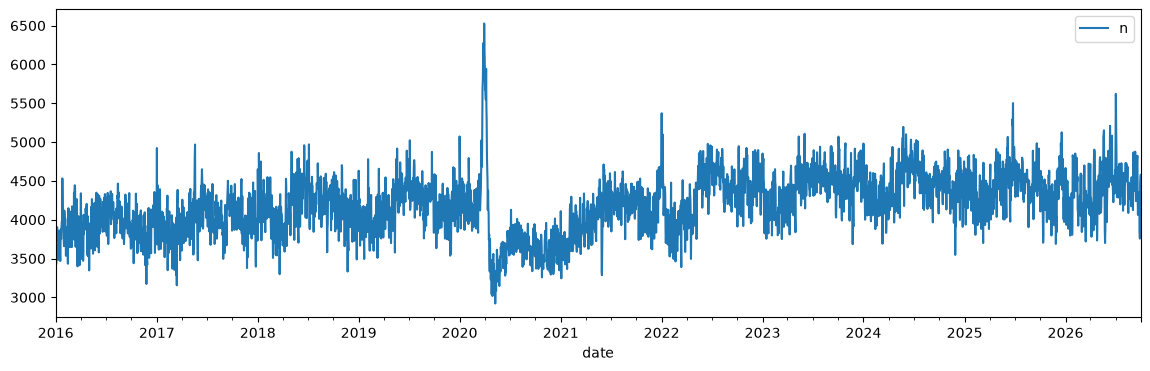

In [28]:
daily.plot(x =  'date', y = 'n', figsize = (14,4))

<Axes: xlabel='date'>

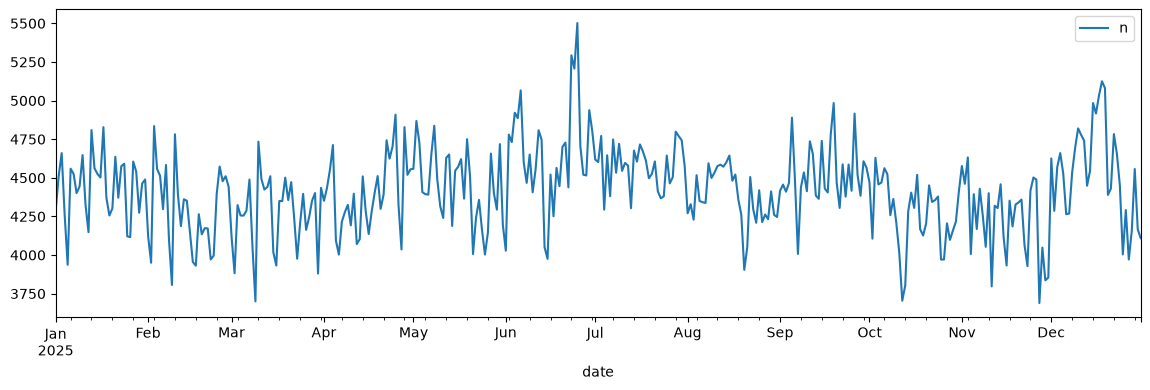

In [29]:
daily_2025 = daily[daily['date'].dt.year == 2025]

daily_2025.plot(x='date', y='n', figsize=(14, 4))

**Вывод:** ... Видна сезонность количества вызовов - пик приходится на середину года с июне-июле, что возможно связано с жарой, второй пик более сглаженный с начала декабря - связан с похолоданием и сезоном ОРВИ
Резкие провалы до ~3 700:
   - в начале марта — 9 марта 2025 года в США переводили часы на летнее время: в 2:00 ночи часы перевели на 3:00, то есть на час вперёд.
   - в конце ноября — 27 ноября отмечается День благодарения

Это календарные эффекты. Праздники и переводы часов меняют число вызовов независимо от погоды. Значит, модели понадобятся признаки «праздник» и, возможно, «перевод часов», иначе она спишет эти провалы на что-то другое.

## 4. День недели

Посчитай **среднее** число вызовов по дням недели на основе таблицы `daily`.

Подсказка: `daily["date"] = pd.to_datetime(daily["date"])`, затем день недели: `daily["date"].dt.day_name()`, дальше `groupby(...)["n"].mean()`.

**Вопрос:** зависит ли нагрузка от дня недели? Почему это важно учитывать в модели?

In [36]:
# ТВОЙ КОД
daily["weekday"] = daily["date"].dt.day_name()
daily.head()

,date,n,weekday
0,2016-01-01,4872,Friday
1,2016-01-02,3428,Saturday
2,2016-01-03,3426,Sunday
3,2016-01-04,3700,Monday
4,2016-01-05,3608,Tuesday


In [37]:
by_weekday = daily.groupby('weekday')['n'].mean()
by_weekday

weekday
Friday       4340.433155
Monday       4284.183601
Saturday     4123.688057
Sunday       3987.877005
Thursday     4246.380357
Tuesday      4222.627451
Wednesday    4252.695187
Name: n, dtype: float64

In [38]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = by_weekday.reindex(order)
by_weekday

weekday
Monday       4284.183601
Tuesday      4222.627451
Wednesday    4252.695187
Thursday     4246.380357
Friday       4340.433155
Saturday     4123.688057
Sunday       3987.877005
Name: n, dtype: float64

<Axes: xlabel='weekday'>

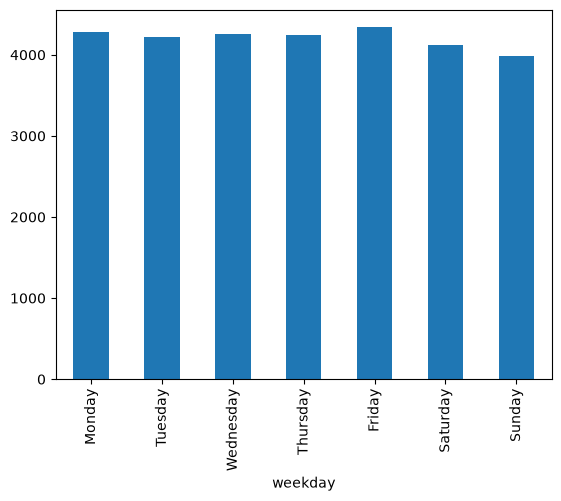

In [ ]:

by_weekday.plot.bar()

**Вывод:** ... к выходным происходит снижение количество вызовов скорей всего связано с уменьшением количества лбдей в центре города, необходимо учитывать в модели дни недели

## 5. Первая проверка гипотезы: температура и вызовы

1. Загрузи погоду: `weather = pd.read_parquet(WEATHER)` и оставь только Манхэттен (как температуру «по городу»).
2. Соедини `daily` и погоду по дате: `daily.merge(..., on="date")`.
3. Построй точечный график (scatter): по оси X `temperature_2m_max`, по оси Y число вызовов. Для этого `df.plot.scatter(x=..., y=..., alpha=0.2)`.
4. Чтобы COVID не мешал, построй график только для 2022–2025 годов.

**Вопросы:** как выглядит зависимость — прямая линия, U-образная или «хоккейная клюшка»? С какой температуры вызовов становится заметно больше? Почему могут расти вызовы и в сильный холод?

In [46]:
# ТВОЙ КОД
weather = pd.read_parquet(WEATHER)
weather_mh = weather[weather["borough"] == 'MANHATTAN']

In [51]:
df = daily.merge(weather_mh, on = 'date')
df.head()
len(df)

3926

<Axes: xlabel='temperature_2m_max', ylabel='n'>

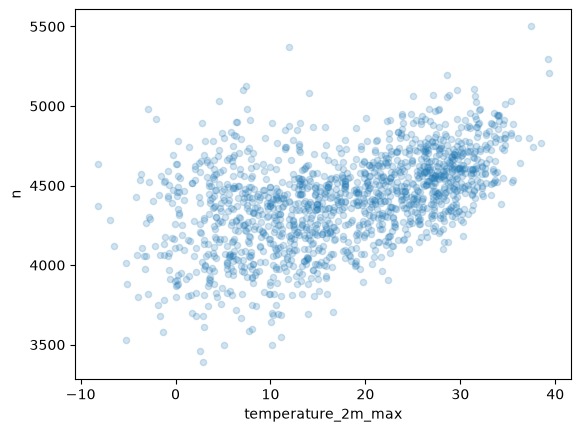

In [54]:
df_2225 = df[(df['date'].dt.year <= 2025) & (df['date'].dt.year >= 2022)] 
df_2225.plot.scatter(x="temperature_2m_max", y="n", alpha=0.2)

<Axes: xlabel='temperature_2m_max'>

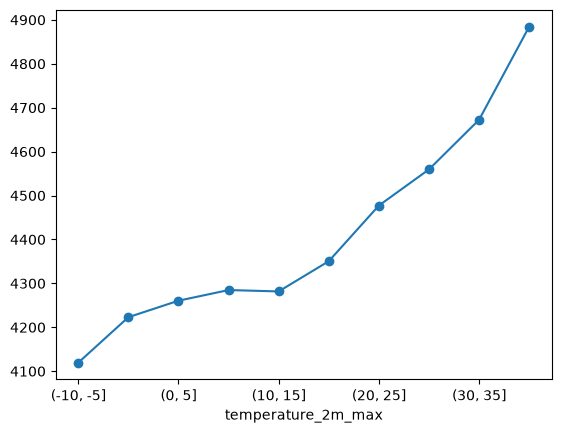

In [55]:
bins = pd.cut(df_2225["temperature_2m_max"], bins=range(-10, 45, 5))
df_2225.groupby(bins)["n"].mean().plot(marker="o")

In [56]:
df_2225.nlargest(5, "n")[["date", "n", "temperature_2m_max"]]

,date,n,temperature_2m_max
3463,2025-06-25,5502,37.4
2192,2022-01-01,5371,11.9
3461,2025-06-23,5293,39.2
3462,2025-06-24,5207,39.3
3066,2024-05-24,5195,28.6


**Вывод:** ... зависимость выглядит как хоккейная клюжка, примерно до 20 градусов идет плато, а затем увеличение при +35…+40 °C вызовов на 14 % больше, чем в комфортную погоду.
При этом нет увеличения вызов при сильном холоде
1. Объяснение выброса при +12 °C: 1 января 2022 года, Новый год и пик Омикрона.
2. Ограничение: при +35…+40 °C всего 14 дней, поэтому оценка «+14 %» приблизительная. 


## Итоги этапа 2

Напиши 3–5 главных находок о данных. Они станут основой для этапа 3 (очистка) и раздела «Данные» в README.

1. в моделе следует учитывать дни недели, праздники
2. период ковида лучше исключить при COVID была не только «большая нагрузка», а сначала резкий всплеск (март 2020), потом долгий спад (май–декабрь 2020) и всплеск Омикрона (январь 2022). Главное, что в эти периоды поведение людей было ненормальным, поэтому модель на них учить нельзя.
3. - Главная находка про жару: форма зависимости, порог, сколько процентов прироста.
- Что предсказываем: почему не HEAT, а все вызовы (задание 1).
- Тренд: что происходило с числом вызовов с 2016 по 2025 год (задание 2).
- Качество данных: что не так с вызовами STNDBY, какие колонки с пропусками (задание 1).

In [ ]:
cd ~/heat-ems-nyc && claude)